# Lobular or ductal? Dense readouts and token-level explanations

**Task.** Distinguish invasive lobular carcinoma (ILC) from invasive carcinoma of no special type (NST, here "ductal") on TCGA-BRCA H&E slides, and explain both the predictions and the errors.

**Main approaches:**

1. **Dense readouts.** A pathology foundation model encodes a 112 µm tile as 16 × 16 patch tokens of 7 µm, about one nucleus each. A linear head on the mean patch token decomposes exactly into one prediction per token, so the map of token predictions is the tile prediction itself, not an approximation of it. Because lobular and ductal carcinoma are both tumour, a head trained on ductal tumour alone already detects some lobular cells. The token predictions also detect tumour in tiles that the head predicts as another class. A head on the class token offers neither.
2. **Token-level interpretability and debugging.** A single token can be compared with annotated tokens of other patients, and a cell can be moved into other tissue while its own pixels stay the same. These tools show what the encoder represents at a cell, and how much of a cell's prediction comes from its surroundings.

**Outline**

- [0. Data and heads](#section-0). The datasets and the two linear heads.
- [Part A. Dense readouts](#part-a)
  - [1. Classifiers are mean-aggregated MIL](#section-1). A mean-token head decomposes exactly into one prediction per token.
  - [2. Encoder card](#section-2). The five encoders compared on annotations.
  - [3. The ductal head segments tissue from tile labels](#section-3)
  - [4. The ductal head detects some lobular cells](#section-4)
  - [5. The lobular head](#section-5). Correct and incorrect tiles, and training on single or mean tokens.
- [Part B. Token-level interpretability and debugging](#part-b)
  - [6. Querying with tokens](#section-6). A bank of annotated tokens from other patients.
  - [7. Errors of the lobular head](#section-7). Four errors explained with the bank.
  - [8. How much of a cell's prediction comes from its surroundings](#section-8). Cells moved into other tissue.
- [Part C. Limitations of the approach](#part-c)
  - [9. Limitations](#section-9)

Five encoders (H-optimus-0, UNI2-h, Virchow2, Hibou-B, Phikon-v2) separate general findings from properties of one model. Figures show H-optimus-0 unless stated otherwise. Tables show all five.

In [1]:
import base64, io, json, warnings
warnings.filterwarnings('ignore', message='IProgress not found')      # tqdm without notebook widgets
warnings.filterwarnings('ignore', message='n_jobs value')             # UMAP with a fixed seed runs on one thread
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import umap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image, ImageDraw
from timm.layers import SwiGLUPacked
from tqdm import tqdm
from transformers import Dinov2Model, Dinov2WithRegistersModel
from transformers import logging as transformers_logging

transformers_logging.set_verbosity_error()                           # no loading notices from transformers
transformers_logging.disable_progress_bar()

DATA_DIR = Path('data/tiles')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ENCODERS = ['H-optimus-0', 'UNI2-h', 'Virchow2', 'Hibou-B', 'Phikon-v2']
GRID, STEP = 16, 28                  # H-optimus-0 reads a 448 px tile as 16 x 16 tokens of 28 px (7 µm)

TUMOUR_RED, LOBULAR_RED = "#ff0000", "#dfab00"
STROMA, IMMUNE, NECROSIS, FAT, FIBROBLAST = '#b2df8a', '#1f78b4', '#6a3d9a', "#ffea8d", '#33a02c'
TISSUES = ['tumour', 'stroma', 'immune', 'necrosis', 'fat']                       # classes of the ductal head
TISSUE_COLOURS = [TUMOUR_RED, STROMA, IMMUNE, NECROSIS, FAT]
S6 = ['lobular tumour', 'ductal tumour', 'stroma', 'immune', 'necrosis', 'fat']  # classes of the lobular head
S6_COLOURS = [LOBULAR_RED, TUMOUR_RED, STROMA, IMMUNE, NECROSIS, FAT]
NUCLEUS_COLOURS = {'tumour nuclei': TUMOUR_RED, 'lymphocyte nuclei': IMMUNE, 'fibroblast nuclei': FIBROBLAST}

# A dense readout is drawn as one colour per token, the class the head predicts there: TISSUE_RGBA[predictions].
TISSUE_RGBA = np.array([plt.matplotlib.colors.to_rgba(c, 0.45) for c in TISSUE_COLOURS])
S6_RGBA = np.array([plt.matplotlib.colors.to_rgba(c, 0.45) for c in S6_COLOURS])
# A BCSS mask is drawn as MASK_RGB[mask]: the five classes in colour, other annotated tissue (codes 5-8) grey, not annotated (-1) white.
MASK_RGB = np.array([plt.matplotlib.colors.to_rgb(c) for c in TISSUE_COLOURS] + 4 * [(0.85, 0.85, 0.85)] + [(1, 1, 1)])

heads = torch.load('heads/linear_heads.pt', weights_only=True)
DUCTAL_HEADS = {model: [(W.numpy(), b.numpy()) for W, b in folds] for model, folds in zip(ENCODERS, heads['ductal_folds'])}
LOBULAR_HEADS = {model: [(W.numpy(), b.numpy()) for W, b in folds] for model, folds in zip(ENCODERS, heads['lobular_folds'])}
LOBULAR_MEAN_HEADS = {model: [(W.numpy(), b.numpy()) for W, b in folds] for model, folds in zip(ENCODERS, heads['lobular_mean_folds'])}
CLASS_TOKEN_HEADS = {model: [(W.numpy(), b.numpy()) for W, b in folds] for model, folds in zip(ENCODERS, heads['cls_folds'])}

# The fold that left each hospital out. A hospital is the tissue source site, characters 5-6 of a TCGA id.
FOLD = {'A1': 2, 'A2': 0, 'A7': 4, 'A8': 3, 'AC': 2, 'AN': 4, 'AO': 3, 'AQ': 1, 'AR': 1, 'B6': 0, 'BH': 2, 'C8': 0, 'D8': 1,
        'E2': 3, 'E9': 3, 'EW': 4, 'GI': 0, 'GM': 2, 'HN': 3, 'LL': 4, 'LQ': 0, 'OL': 1, 'S3': 0}

<a id="section-0"></a>
## 0. Data and heads

| dataset | annotation | annotated or inferred | use |
|---|---|---|---|
| BCSS, 151 TCGA-BRCA slides | tissue regions (tumour, stroma, immune, necrosis, fat) | annotated polygons, coarse at the scale of a 7 µm token | training the ductal head, tile and token labels |
| NuCLS, 50,490 nuclei in BCSS regions | type of every nucleus; the tumour is almost all ductal | annotated by crowd workers, reviewed by pathologists | evaluation per nucleus, with positives and negatives |
| BEETLE, 10 TCGA and 7 Radboudumc lobular slides | every single lobular tumour cell outlined, in regions of classic ILC | annotated positives; an unoutlined nucleus is not a negative | training the lobular class (5 TCGA slides), evaluation (5 TCGA and 7 Radboudumc slides) |
| TCGA-BRCA slides with coarse tumour outlines (Banerjee et al. 2025) | lobular or ductal per patient | annotated per patient; the type of a tile, token or nucleus is inferred from it | tumour type of tiles |

BEETLE outlines only lobular cells, so false lobular predictions inside lobular regions cannot be measured. False positives are measured only where negatives are annotated, on NuCLS nuclei and BCSS regions. A "ductal tumour nucleus" is a tumour nucleus of a ductal patient.

| head | classes | training data |
|---|---|---|
| ductal head | tumour, stroma, immune, necrosis, fat | mean patch tokens of 7,193 BCSS tiles of ductal patients; tile label = the class covering at least half of the annotated pixels |
| lobular head | lobular tumour, ductal tumour, stroma, immune, necrosis, fat | single tokens: 1,827 outlined single cells on 5 BEETLE TCGA slides (lobular tumour), and up to 20,000 BCSS tokens per class, labelled by the class covering at least half of the token; the tumour of ductal patients is ductal tumour |

Both heads are multinomial logistic regressions on standardised tokens, with class-balanced weights and an L2 penalty selected by cross-validation over hospitals. Each head is trained five times, each time without one of five hospital groups, and every tile is predicted by the model that did not see its hospital. The lobular head is trained on single tokens, but it is linear, so its tile prediction on the mean token is still the mean of its token predictions. It is the model for the task. Section 5 compares it with the same head trained on mean tokens. The ductal head shows what tumour labels alone achieve.

Change the base path here:

In [2]:
BASE_PATH = Path.home() / 'Projects/data/'

# Local copies of the datasets (README.md says where to get them). Set BASE_PATH, or each path, to your own copies.
DATASETS = {'tcga_slides': BASE_PATH / 'tcga_brca_hoptimus0/slides',   # TCGA-BRCA diagnostic slides, <slide id>.svs
            'bcss':        BASE_PATH / 'bcss',                         # BCSS: masks/, rgbs_raw/, meta/
            'nucls':       BASE_PATH / 'nucls/NuCLS_dataset',          # NuCLS: csv/, rgb/
            'beetle':      BASE_PATH / 'beetle'}                       # BEETLE: annotations.zip

The notebook ships the heads, the list of bank tokens (section 6) and the tables of section 2, which rest on about 20,000 tiles. `reproduce.py` recomputes all three from the datasets. Everything else is computed here, from tiles cut from local copies of the same datasets.


In [3]:
from fetch_tiles import fetch_tiles      # cuts each tile and its annotation from local copies of the datasets

# what fetch_tiles.py reads from each dataset
required = [DATASETS['tcga_slides'],
            DATASETS['bcss'] / 'masks', DATASETS['bcss'] / 'rgbs_raw', DATASETS['bcss'] / 'meta/roiBounds_BaseMagnification.csv',
            DATASETS['nucls'] / 'csv', DATASETS['nucls'] / 'rgb',
            DATASETS['beetle'] / 'annotations.zip']
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError('Dataset files not found (see README.md, Datasets):\n' + '\n'.join(missing))

# Every tile of this notebook: name -> (source, slide id, x, y, size in µm)
#   bcss:    (x, y) is the tile centre in the BCSS region image (0.30 µm/px); cached with its region mask and NuCLS nuclei
#   beetle:  (x, y) is the top-left level-0 pixel of the tile on the slide; cached with BEETLE's invasive tumour outlines
TILE_SPECS = {
    'bcss_E2-A158':                 ('bcss',    'TCGA-E2-A158-01Z-00-DX1.994C60FE-E651-4224-95E7-4669834F2338', 560,       1008,     134.4),
    'bcss_E2-A1LI':                 ('bcss',    'TCGA-E2-A1LI-01Z-00-DX1.503dd2fa-23ef-4b11-8aab-301e069eaa88', 3472,      1120,     134.4),
    'ductal_tumour_AO-A0J6':        ('bcss',    'TCGA-AO-A0J6-01Z-00-DX1.D0C003CE-E112-4375-953D-78404C9D62DA', 4048,      1491,     134.4),
    'beetle_A2-A0YK':               ('beetle',  'TCGA-A2-A0YK-01Z-00-DX1.FB23FC30-B3B2-452A-A6B0-94129B333207', 37955,     39968,    112.0),
    'beetle_AC-A5XS':               ('beetle',  'TCGA-AC-A5XS-01Z-00-DX1.E5F2481E-9314-4B20-84B7-370EF82AF4BB', 8949,      16761,    112.0),
    'beetle_A2-A0EP':               ('beetle',  'TCGA-A2-A0EP-01Z-00-DX1.1180C406-5C18-4373-8621-1B7B70875113', 70284,     61968,    112.0),
    'beetle_AC-A2FE':               ('beetle',  'TCGA-AC-A2FE-01Z-00-DX1.C036AE58-3C0D-4DBF-B658-296D03FD6701', 38876,     15656,    112.0),
    'beetle_AR-A2LK':               ('beetle',  'TCGA-AR-A2LK-01Z-00-DX1.FBD59C38-CD4E-4C22-BC74-A57C192A9BBC', 18484,     11364,    112.0),
    'lobular_most_lobular_A2-A0YK': ('beetle',  'TCGA-A2-A0YK-01Z-00-DX1.FB23FC30-B3B2-452A-A6B0-94129B333207', 37954.57,  41309.71, 112.0),
    'lobular_most_ductal_AC-A2FE':  ('beetle',  'TCGA-AC-A2FE-01Z-00-DX1.C036AE58-3C0D-4DBF-B658-296D03FD6701', 38875.68,  15656.00, 112.0),
    'ductal_most_ductal_BH-A0B9':   ('bcss',    'TCGA-BH-A0B9-01Z-00-DX1.C23ADB4C-52D4-4DFD-B8E3-156E43F0E645', 2626.00,   1581.00,  134.4),
    'ductal_most_lobular_A7-A4SE':  ('bcss',    'TCGA-A7-A4SE-01Z-00-DX1.16BC8401-E40E-4A1A-9BD9-12735C9AE3F6', 224.00,    224.00,   134.4),
    'cell_called_stroma_AC-A2FE':   ('beetle',  'TCGA-AC-A2FE-01Z-00-DX1.C036AE58-3C0D-4DBF-B658-296D03FD6701', 41908,     20004,    112.0),
    'cell_called_ductal_A2-A0EP':   ('beetle',  'TCGA-A2-A0EP-01Z-00-DX1.1180C406-5C18-4373-8621-1B7B70875113', 71196,     61512,    112.0),
    'nucleus_called_lobular_A7-A26I': ('bcss', 'TCGA-A7-A26I-01Z-00-DX1.0077D012-BC14-4E96-84F7-A1A6A3A778DF', 1167, 753, 134.4),
    # section 8: one host tile of each kind, from patients other than those of the two cells
    'host_ductal_BH-A0RX':  ('bcss',   'TCGA-BH-A0RX-01Z-00-DX1.B4ABAFB9-6696-4F22-9468-DA56E1AD32D3', 2016,     672,      134.4),
    'host_lobular_A8-A0AB': ('beetle', 'TCGA-A8-A0AB-01Z-00-DX1.103ED338-A0F9-403B-A10C-49840BD60EB8', 22692.0,  10872.0,  112.0),
    'host_stroma_AO-A0J6':  ('bcss',   'TCGA-AO-A0J6-01Z-00-DX1.D0C003CE-E112-4375-953D-78404C9D62DA', 4256,     224,      134.4),
}
HOSPITAL = {name: spec[1][5:7] for name, spec in TILE_SPECS.items()}
PATIENT = {name: spec[1][:12] for name, spec in TILE_SPECS.items()}

# Each tile is cached as {name}.png, {name}_annotation.json and, for BCSS tiles, {name}_mask.npy (448 x 448).
# The annotation holds outlines in tile pixels, empty where the tile's dataset has none:
#   single lobular cells   BEETLE invasive tumour outlines (label 3) of at most 200 µm² whose centre lies inside the tile
#   tumour outlines        every BEETLE invasive tumour outline touching the tile, single cells and clusters
#   ... nuclei             NuCLS nuclei whose centre lies inside the tile: tumour, lymphocyte, fibroblast and other nuclei
fetch_tiles(TILE_SPECS, DATA_DIR, DATASETS, desc='notebook tiles')
print(f'{len(TILE_SPECS)} tiles and their annotations cached in {DATA_DIR}')

18 tiles and their annotations cached in data/tiles


The five foundation models are loaded in `float16`. `MODELS` holds each encoder with its settings, and `encode(encoder, tiles)` returns the patch tokens of a list of tiles. Each cell below reads the tiles it shows from `data/tiles/` and encodes them itself.

In [4]:
# Each encoder: the network in float16, its input normalisation, the number of tokens before the patch tokens (class and register
# tokens), the side of its patch grid on a 224 px input, and whether it is a timm model (patch tokens from forward_features)
# or a transformers model (patch tokens from last_hidden_state).
MODELS = {
    'H-optimus-0': {'net': timm.create_model('hf-hub:bioptimus/H-optimus-0', pretrained=True, init_values=1e-5, dynamic_img_size=False).eval().half(),
                    'mean': (0.707223, 0.578729, 0.703617), 'std': (0.211883, 0.230117, 0.177517), 'prefix': 5, 'grid': 16, 'timm': True},
    'UNI2-h':      {'net': timm.create_model('hf-hub:MahmoodLab/UNI2-h', pretrained=True, img_size=224, patch_size=14, depth=24, num_heads=24,
                                             init_values=1e-5, embed_dim=1536, mlp_ratio=2.66667 * 2, num_classes=0, no_embed_class=True,
                                             mlp_layer=SwiGLUPacked, act_layer=torch.nn.SiLU, reg_tokens=8, dynamic_img_size=True).eval().half(),
                    'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'prefix': 9, 'grid': 16, 'timm': True},
    'Virchow2':    {'net': timm.create_model('hf-hub:paige-ai/Virchow2', pretrained=True, mlp_layer=SwiGLUPacked, act_layer=torch.nn.SiLU).eval().half(),
                    'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'prefix': 5, 'grid': 16, 'timm': True},
    'Hibou-B':     {'net': Dinov2WithRegistersModel.from_pretrained('histai/hibou-b').eval().half(),
                    'mean': (0.7068, 0.5755, 0.722), 'std': (0.195, 0.2316, 0.1816), 'prefix': 5, 'grid': 16, 'timm': False},
    'Phikon-v2':   {'net': Dinov2Model.from_pretrained('owkin/phikon-v2').eval().half(),
                    'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'prefix': 1, 'grid': 14, 'timm': False},
}


@torch.no_grad()
def encode(model, imgs, device=DEVICE, batch_size=8):
    """Patch tokens (B, N, D) of a list of 448 px tiles, each read at 224 px as in training.
    The network is on the GPU only during the call, so the five encoders never share it."""
    net = model['net'].to(device)
    mean = torch.tensor(model['mean'], device=device)[:, None, None]
    std = torch.tensor(model['std'], device=device)[:, None, None]
    patches = []
    for start in tqdm(range(0, len(imgs), batch_size), desc='encoding', unit='batch', mininterval=5, disable=len(imgs) < 100):   # progress for long lists
        batch = np.stack([np.array(Image.fromarray(img).resize((224, 224), Image.Resampling.BILINEAR)) for img in imgs[start:start + batch_size]])
        x = torch.as_tensor(batch, device=device).permute(0, 3, 1, 2).float() / 255
        x = ((x - mean) / std).half()
        if model['timm']:
            out = net.forward_features(x)
        else:
            out = net(x).last_hidden_state
        patches.append(out[:, model['prefix']:].float().cpu().numpy())
    net.to('cpu')
    torch.cuda.empty_cache()
    return np.concatenate(patches)


img = np.asarray(Image.open(DATA_DIR / 'bcss_E2-A158.png'))
for encoder_name, encoder in MODELS.items():
    print(f'{encoder_name:12s} patch tokens per tile: {encode(encoder, [img])[0].shape}')

H-optimus-0  patch tokens per tile: (256, 1536)


UNI2-h       patch tokens per tile: (256, 1536)


Virchow2     patch tokens per tile: (256, 1280)
Hibou-B      patch tokens per tile: (256, 768)


Phikon-v2    patch tokens per tile: (196, 1024)


<a id="part-a"></a>
# Part A. Dense readouts

<a id="section-1"></a>
## 1. Classifiers are mean-aggregated MIL

A linear classifier applied to the mean of the patch tokens equals the mean of the classifier applied to each token.

$$\text{clf}\left(\frac{1}{N}\sum_{i=1}^N \mathbf{z}_i\right) = \frac{1}{N}\sum_{i=1}^N \text{clf}(\mathbf{z}_i)$$

A head trained on mean patch tokens is therefore a multiple-instance model with mean aggregation. Applied to each token, it gives that token's exact contribution to the tile prediction. We call the map of token predictions the dense readout. The cell below checks the identity for the ductal head on one tile.

In [5]:
name = 'bcss_E2-A158'
img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
tokens = encode(MODELS['H-optimus-0'], [img])[0]
W, b = DUCTAL_HEADS['H-optimus-0'][FOLD[HOSPITAL[name]]]       # the fold that left this tile's hospital out

tile_logits = tokens.mean(axis=0) @ W + b
token_logits = tokens @ W + b
print('head on the mean token    ', np.round(tile_logits, 4))
print('mean of the token readouts', np.round(token_logits.mean(axis=0), 4))
print('largest difference        ', np.abs(tile_logits - token_logits.mean(axis=0)).max())

head on the mean token     [-0.9224  2.2144  2.2016 -2.5492 -0.9444]
mean of the token readouts [-0.9224  2.2144  2.2016 -2.5492 -0.9444]
largest difference         1.9073486e-06


The two agree to float precision. The dense readout assigns each token the class with the highest logit (16 × 16 tokens per tile, 14 × 14 for Phikon-v2).

**Class token.** The common alternative is a head on the class token. We trained one on the class token of each encoder, with the same tiles, labels and folds as the ductal head. Its tile predictions reach a balanced accuracy of 0.86–0.88, against 0.89–0.91 for the ductal head. Applied to the patch tokens, it does not reproduce its own tile prediction. The mean of its token predictions agrees with it on only 35–71% of tiles. Its token predictions also localise poorly. Averaged over the five classes, 20–42% of annotated BCSS tokens are assigned their own class, against 79–82% for the ductal head. On NuCLS, it ranks tumour nuclei against the other nuclei of the same tile with a within-tile AUROC of 0.45–0.56, against 0.87–0.89. The class token summarises the tile, while the patch tokens retain the cells. The figure compares both heads on one tile.

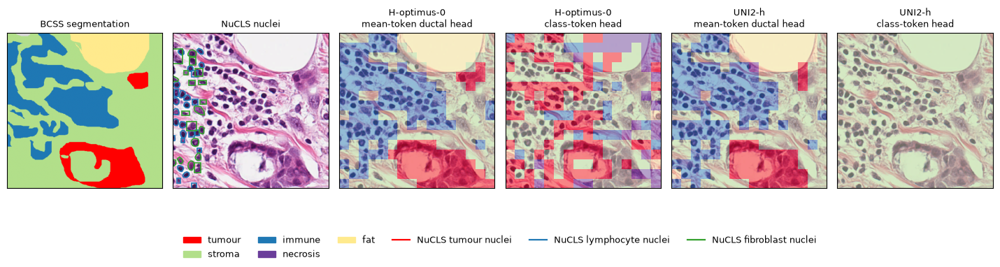

In [6]:
name = 'bcss_E2-A158'
img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
mask = np.load(DATA_DIR / f'{name}_mask.npy')
annotation = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())
fold = FOLD[HOSPITAL[name]]

fig, axes = plt.subplots(1, 6, figsize=(14.4, 3.6))
axes[0].imshow(MASK_RGB[mask])
axes[0].set_title('BCSS segmentation', fontsize=9.5)
axes[1].imshow(img)
for kind, colour in NUCLEUS_COLOURS.items():
    for poly in annotation[kind]:
        axes[1].add_patch(plt.Polygon(poly, fill=False, ec=colour, lw=1.2))
axes[1].set_title('NuCLS nuclei', fontsize=9.5)

for col, encoder_name in [(2, 'H-optimus-0'), (4, 'UNI2-h')]:
    tokens = encode(MODELS[encoder_name], [img])[0]
    for ax, model_heads, title in [(axes[col], DUCTAL_HEADS, 'mean-token ductal head'), (axes[col + 1], CLASS_TOKEN_HEADS, 'class-token head')]:
        W, b = model_heads[encoder_name][fold]
        predictions = (tokens @ W + b).argmax(axis=1)
        ax.imshow(img)
        ax.imshow(TISSUE_RGBA[predictions].reshape(GRID, GRID, 4), extent=(0, 448, 448, 0), interpolation='nearest')
        ax.set_title(f'{encoder_name}\n{title}', fontsize=9)

handles = [Patch(color=c, label=t) for t, c in zip(TISSUES, TISSUE_COLOURS)]
handles += [Line2D([], [], color=c, lw=1.6, label=f'NuCLS {kind}') for kind, c in NUCLEUS_COLOURS.items()]
plt.setp(axes.flat, xticks=[], yticks=[], xlim=(0, 448), ylim=(448, 0))
fig.tight_layout(rect=(0, 0.8 / fig.get_figheight(), 1, 1))   # room for the legend below
fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, fontsize=9)
plt.show()

<a id="section-2"></a>
## 2. Encoder card

The card compares the encoders for each head and tumour type, using only measures that rest on annotations. The target class is tumour for the ductal head, and ductal or lobular tumour for the lobular head.

- **Tile acc.** Share of tiles of the target class predicted as that class.
- **Loc.** Share of annotated target tokens predicted as the target class. An outlined cell is evaluated at the token of its centre.
- **FG Det., outvoted.** Among tiles that contain annotated target tissue but are predicted as another class, the share in which at least one annotated target token is still predicted as the target class. It measures what the dense readout finds where the tile prediction finds nothing.
- **Tumour type.** For tiles inside coarse tumour outlines, whether the tile's lobular − ductal logit agrees with the patient's diagnosis. These tiles contain much stroma, so a head predicts many of them as stroma even when it is right. The tumour type is the fairer measure for them.

BCSS tiles are labelled by the class covering at least half of their annotated pixels. We do not aggregate the readout into a slide-level score. The task weights explanation over performance, the readout can be checked against annotations at the token and the tile, and a score over coarse outlines would be dominated by stroma. The best encoder per row is in bold. The tables rest on about 20,000 tiles and are reported as computed by `reproduce.py`.

**Ductal head, ductal tumour (BCSS tiles and tokens, NuCLS nuclei)**

| | H-optimus-0 | UNI2-h | Virchow2 | Hibou-B | Phikon-v2 |
|---|---|---|---|---|---|
| Tile acc., balanced over five classes | 0.89 | **0.91** | 0.89 | 0.89 | 0.89 |
| Loc., tumour tokens | 0.82 | 0.80 | **0.84** | 0.82 | 0.80 |
| FG Det., outvoted tiles | 0.95 | 0.93 | 0.93 | **0.96** | 0.96 |
| NuCLS tumour nuclei predicted as tumour | 0.89 | 0.89 | **0.92** | 0.88 | 0.88 |
| NuCLS fibroblast nuclei predicted as tumour | **0.08** | 0.09 | 0.11 | 0.08 | 0.09 |

**Ductal head on lobular slides, lobular tumour counted as tumour (BEETLE)**

| | H-optimus-0 | UNI2-h | Virchow2 | Hibou-B | Phikon-v2 |
|---|---|---|---|---|---|
| Loc., outlined lobular cells predicted as tumour (TCGA) | 0.22 | 0.27 | 0.37 | 0.19 | **0.40** |
| FG Det., outvoted tiles (TCGA) | 0.55 | 0.71 | 0.79 | 0.64 | **0.85** |
| Loc., outlined lobular cells predicted as tumour (Radboudumc) | 0.20 | 0.25 | **0.28** | 0.17 | 0.26 |
| FG Det., outvoted tiles (Radboudumc) | 0.63 | 0.77 | 0.74 | 0.66 | **0.78** |

**Lobular head, ductal and lobular tumour**

| | H-optimus-0 | UNI2-h | Virchow2 | Hibou-B | Phikon-v2 |
|---|---|---|---|---|---|
| Tile acc., balanced over five classes (tumours merged) | **0.91** | 0.91 | 0.90 | 0.89 | 0.89 |
| Tumour type, ductal patients' outline tiles with lobular < ductal | 0.77 | 0.73 | 0.74 | 0.73 | **0.84** |
| Tumour type, lobular patients' outline tiles with lobular > ductal | 0.60 | **0.67** | 0.59 | 0.53 | 0.42 |
| Loc., ductal: BCSS tumour tokens of ductal patients predicted as ductal | **0.88** | 0.87 | 0.88 | 0.87 | 0.88 |
| Loc., lobular: outlined lobular cells predicted as lobular (TCGA) | 0.73 | **0.74** | 0.66 | 0.57 | 0.53 |
| Loc., lobular: outlined lobular cells predicted as lobular (Radboudumc) | **0.87** | 0.85 | 0.82 | 0.62 | 0.26 |
| FG Det., ductal, outvoted tiles | **0.90** | 0.90 | 0.90 | 0.87 | 0.90 |
| FG Det., lobular, outvoted tiles (TCGA) | 0.89 | **0.93** | 0.78 | 0.84 | 0.62 |
| FG Det., lobular, outvoted tiles (Radboudumc) | **0.98** | 0.98 | 0.89 | 0.94 | 0.65 |
| BCSS stroma tokens predicted as lobular | 0.01 | 0.02 | 0.02 | 0.02 | **0.00** |
| NuCLS tumour nuclei of ductal patients predicted as lobular | 0.01 | 0.01 | 0.01 | 0.01 | **0.00** |
| NuCLS fibroblast nuclei predicted as tumour | 0.10 | 0.11 | 0.11 | 0.12 | **0.08** |


- **The dense readout detects tumour that the tile prediction misses.** The ductal head predicts 2,866 of the 6,612 BCSS tiles with annotated tumour as another class, and in 93–96% of them the dense readout still finds annotated tumour. The lobular head predicts 156 of 164 BEETLE tiles with outlined lobular cells as another class, mostly stroma, and in 62–93% of them it still finds an outlined cell.
- **Tumour labels alone detect some lobular cells.** The ductal head was trained on no lobular tile, yet predicts 19–40% of outlined lobular cells as tumour.
- **The lobular head separates the two tumours at the token.** It predicts 87–88% of ductal tumour tokens as ductal and 53–74% of outlined lobular cells as lobular. It rarely predicts stroma or ductal nuclei as lobular (at most 2%).
- **The tumour type of coarse outline tiles is right more often for ductal than for lobular patients.** Tiles of ductal patients receive the correct tumour type in 73–84% of cases, tiles of lobular patients in 42–67%.
- **No encoder is best throughout.** For tissue classes the choice hardly matters. For lobular cells, UNI2-h detects the most on TCGA (0.74), and the ranking changes on Radboudumc's scanner (H-optimus-0 0.87, Phikon-v2 0.26). The encoder therefore has to be chosen for the structure, the labels and the scanner at hand. Part B uses H-optimus-0.

<a id="section-3"></a>
## 3. The ductal head segments tissue from tile labels

The ductal head learned five tissue classes from BCSS tiles of ductal patients, one label per tile. Its tumour class therefore represents ductal tumour. The figure shows its dense readout for all five encoders on a BCSS tile of TCGA-E2-A1LI, mostly tumour with fat and immune cells, with the pathologists' segmentation and the NuCLS nuclei. The second row is a tumour tile of another ductal patient.

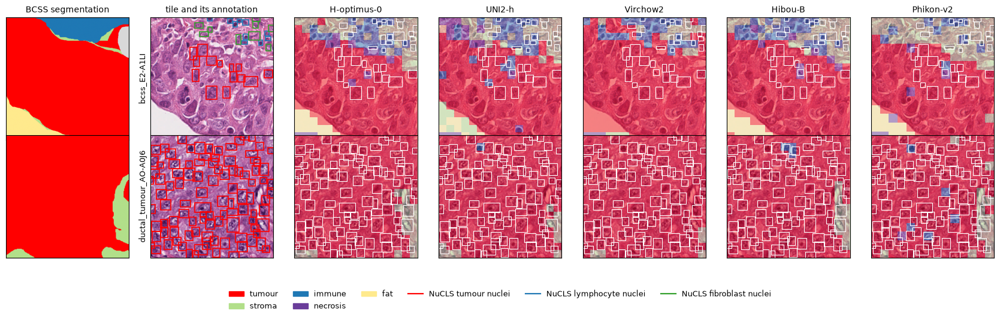

In [7]:
names = ['bcss_E2-A1LI', 'ductal_tumour_AO-A0J6']
fig, axes = plt.subplots(len(names), 7, figsize=(16.8, 2.6 * len(names)))
for row, name in zip(axes, names):
    img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
    mask = np.load(DATA_DIR / f'{name}_mask.npy')
    annotation = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())
    all_nuclei = annotation['tumour nuclei'] + annotation['lymphocyte nuclei'] + annotation['fibroblast nuclei'] + annotation['other nuclei']

    row[0].imshow(MASK_RGB[mask])
    row[1].imshow(img)
    for kind, colour in NUCLEUS_COLOURS.items():
        for poly in annotation[kind]:
            row[1].add_patch(plt.Polygon(poly, fill=False, ec=colour, lw=1.2))
    row[1].set_ylabel(name, fontsize=9)

    for ax, encoder_name in zip(row[2:], ENCODERS):
        encoder = MODELS[encoder_name]
        tokens = encode(encoder, [img])[0]
        W, b = DUCTAL_HEADS[encoder_name][FOLD[HOSPITAL[name]]]
        predictions = (tokens @ W + b).argmax(axis=1)
        ax.imshow(img)
        ax.imshow(TISSUE_RGBA[predictions].reshape(encoder['grid'], encoder['grid'], 4), extent=(0, 448, 448, 0), interpolation='nearest')
        for poly in all_nuclei:
            ax.add_patch(plt.Polygon(poly, fill=False, ec='white', lw=0.8))
for ax, title in zip(axes[0], ['BCSS segmentation', 'tile and its annotation'] + ENCODERS):
    ax.set_title(title, fontsize=10)

handles = [Patch(color=c, label=t) for t, c in zip(TISSUES, TISSUE_COLOURS)]
handles += [Line2D([], [], color=c, lw=1.6, label=f'NuCLS {kind}') for kind, c in NUCLEUS_COLOURS.items()]
plt.setp(axes.flat, xticks=[], yticks=[], xlim=(0, 448), ylim=(448, 0))
fig.tight_layout(rect=(0, 0.8 / fig.get_figheight(), 1, 1))
fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, fontsize=9)
plt.show()

<a id="section-4"></a>
## 4. The ductal head detects some lobular cells

Does the tumour class, learned from ductal tumour only, detect lobular tumour cells? The figure shows one tile from each of the five BEETLE TCGA patients (the tile with the most outlined single cells). Below each readout is the number of outlined cells predicted as tumour.

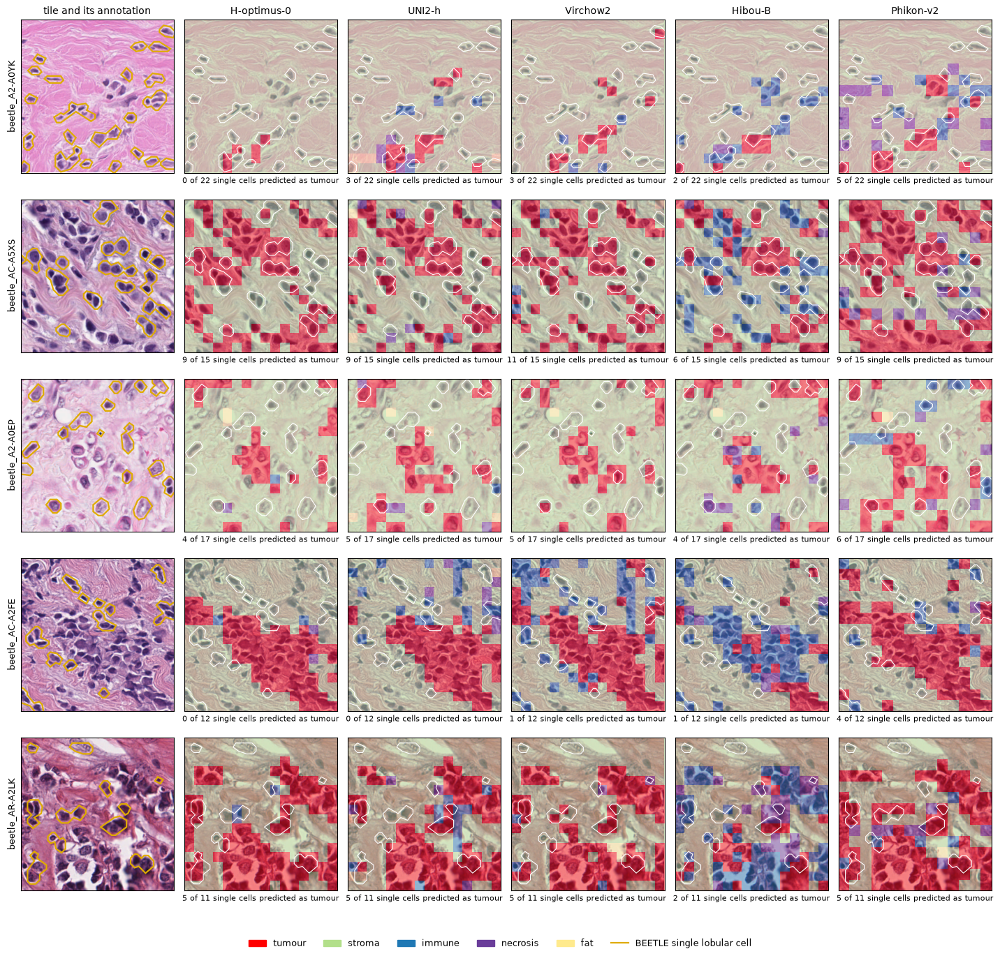

In [8]:
names = ['beetle_A2-A0YK', 'beetle_AC-A5XS', 'beetle_A2-A0EP', 'beetle_AC-A2FE', 'beetle_AR-A2LK']
fig, axes = plt.subplots(len(names), 6, figsize=(14.4, 2.75 * len(names)))
for row, name in zip(axes, names):
    img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
    cells = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())['single lobular cells']
    centres = np.array([np.mean(cell, axis=0) for cell in cells])

    row[0].imshow(img)
    for cell in cells:
        row[0].add_patch(plt.Polygon(cell, fill=False, ec=LOBULAR_RED, lw=1.6))
    row[0].set_ylabel(name, fontsize=9)

    for ax, encoder_name in zip(row[1:], ENCODERS):
        encoder = MODELS[encoder_name]
        tokens = encode(encoder, [img])[0]
        grid, step = encoder['grid'], 448 // encoder['grid']
        W, b = DUCTAL_HEADS[encoder_name][FOLD[HOSPITAL[name]]]
        predictions = (tokens @ W + b).argmax(axis=1)
        at_cells = predictions[(centres[:, 1] // step).astype(int) * grid + (centres[:, 0] // step).astype(int)]   # the token at each cell's centre
        ax.imshow(img)
        ax.imshow(TISSUE_RGBA[predictions].reshape(grid, grid, 4), extent=(0, 448, 448, 0), interpolation='nearest')
        for cell in cells:
            ax.add_patch(plt.Polygon(cell, fill=False, ec='white', lw=0.8))
        ax.set_xlabel(f'{(at_cells == 0).sum()} of {len(at_cells)} single cells predicted as tumour', fontsize=8)
for ax, title in zip(axes[0], ['tile and its annotation'] + ENCODERS):
    ax.set_title(title, fontsize=10)

handles = [Patch(color=c, label=t) for t, c in zip(TISSUES, TISSUE_COLOURS)]
handles += [Line2D([], [], color=LOBULAR_RED, lw=1.6, label='BEETLE single lobular cell')]
plt.setp(axes.flat, xticks=[], yticks=[], xlim=(0, 448), ylim=(448, 0))
fig.tight_layout(rect=(0, 0.55 / fig.get_figheight(), 1, 1))
fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, fontsize=9)
plt.show()

Where lobular cells lie together, the ductal head predicts them as tumour. This holds for 6–11 of the 15 cells in the sheet of AC-A5XS, and for the dense groups of AC-A2FE and AR-A2LK. Where single cells lie scattered in collagen, it predicts them as stroma. Only 0–5 of 22 cells on A2-A0YK are predicted as tumour, 4–6 of 17 on A2-A0EP, and 0–4 of the 12 cells around the group on AC-A2FE. All five encoders fail at the same cells, so the failure is not specific to one encoder. Hibou-B additionally predicts many dense lobular cells as immune cells. Across the BEETLE evaluation slides, the ductal head predicts 19–40% of outlined lobular cells as tumour (section 2). A tumour class learned from ductal tumour reaches lobular cells that form tumour tissue, but not single lobular cells scattered in collagen.

<a id="section-5"></a>
## 5. The lobular head

The lobular head adds a lobular class and assigns the tumour of ductal patients to the ductal class. Unlike the ductal head, it is trained on single tokens, namely the token at the centre of each outlined lobular cell and BCSS tokens covered by one class (section 0). Its lobular class is therefore learned from cells, not from tile labels, and each explanation can be checked against an annotation. The end of this section compares it with a lobular head trained on tile labels. Part B examines the single-token head.

**Correct and incorrect tiles.** We rank annotated tiles by the lobular head's tile score, the `lobular − ductal` logit of the mean token, and show the most extreme tile of each kind.

- **Lobular patients:** the highest and the lowest scoring of the 69 BEETLE TCGA tiles with at least ten outlined cells (59 of them score above zero).
- **Ductal patients:** the lowest scoring of 1,701 NuCLS tiles of ductal patients, and the highest scoring of 3,190 BCSS tumour tiles of ductal patients (2 and 2 of them are predicted as lobular).

Each row shows the tile, its annotation and the lobular head's dense readout for each encoder, with the tile score and the share of annotated tumour tokens predicted as lobular.

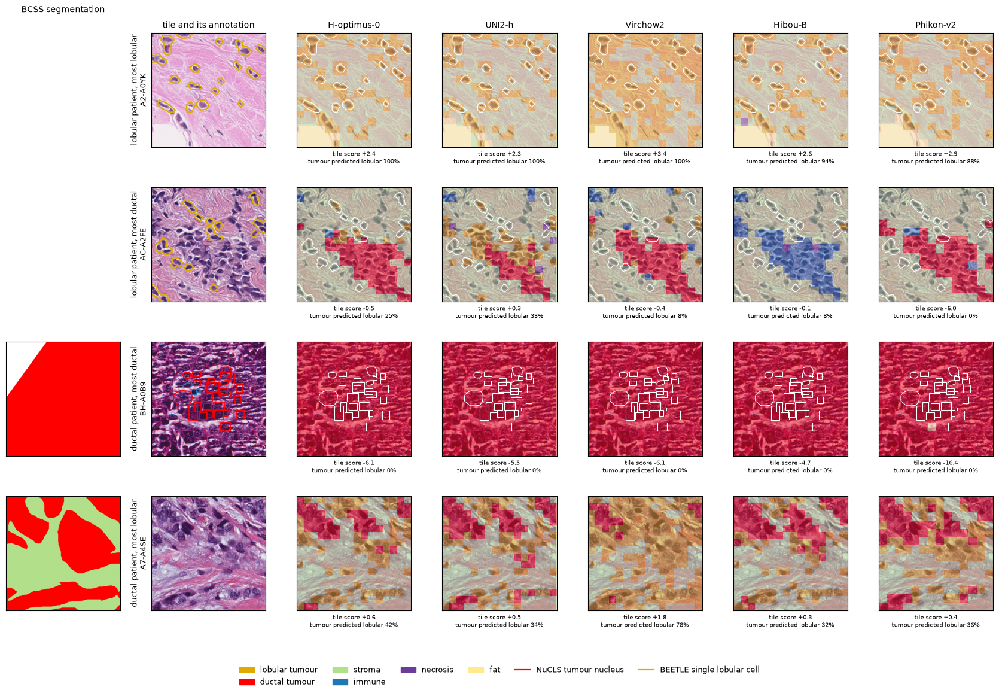

In [9]:
# each example: tile -> row label, and where its annotated tumour lies
EXAMPLES = {'lobular_most_lobular_A2-A0YK': ('lobular patient, most lobular', 'single lobular cells'),
            'lobular_most_ductal_AC-A2FE': ('lobular patient, most ductal', 'single lobular cells'),
            'ductal_most_ductal_BH-A0B9': ('ductal patient, most ductal', 'tumour nuclei'),
            'ductal_most_lobular_A7-A4SE': ('ductal patient, most lobular', 'BCSS tumour')}

fig, axes = plt.subplots(len(EXAMPLES), 7, figsize=(16.8, 2.9 * len(EXAMPLES)))
for row, (name, (verdict, tumour_source)) in zip(axes, EXAMPLES.items()):
    img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
    annotation = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())

    if tumour_source == 'BCSS tumour':                                 # the centres of the tokens at least half inside BCSS tumour
        blocks = np.load(DATA_DIR / f'{name}_mask.npy').reshape(GRID, STEP, GRID, STEP).swapaxes(1, 2).reshape(GRID * GRID, -1)
        tumour_tokens = np.flatnonzero((blocks == 0).mean(axis=1) >= 0.5)
        centres = np.stack([(tumour_tokens % GRID + 0.5) * STEP, (tumour_tokens // GRID + 0.5) * STEP], axis=1)
        tumour_outlines = []
    else:                                                              # the centres of the outlined cells or nuclei
        tumour_outlines = annotation[tumour_source]
        centres = np.array([np.mean(poly, axis=0) for poly in tumour_outlines])

    if TILE_SPECS[name][0] == 'bcss':                                  # BEETLE tiles have no tissue segmentation
        row[0].imshow(MASK_RGB[np.load(DATA_DIR / f'{name}_mask.npy')])
    else:
        row[0].axis('off')
    row[1].imshow(img)
    for kind, colour in NUCLEUS_COLOURS.items():
        for poly in annotation[kind]:
            row[1].add_patch(plt.Polygon(poly, fill=False, ec=colour, lw=1.2))
    for cell in annotation['single lobular cells']:
        row[1].add_patch(plt.Polygon(cell, fill=False, ec=LOBULAR_RED, lw=1.6))
    row[1].set_ylabel(f"{verdict}\n{PATIENT[name][5:]}", fontsize=9)

    for ax, encoder_name in zip(row[2:], ENCODERS):
        encoder = MODELS[encoder_name]
        tokens = encode(encoder, [img])[0]
        grid, step = encoder['grid'], 448 // encoder['grid']
        W, b = LOBULAR_HEADS[encoder_name][FOLD[HOSPITAL[name]]]
        predictions = (tokens @ W + b).argmax(axis=1)
        tile_logits = tokens.mean(axis=0) @ W + b
        at_tumour = predictions[np.unique((centres[:, 1] // step).astype(int) * grid + (centres[:, 0] // step).astype(int))]
        ax.imshow(img)
        ax.imshow(S6_RGBA[predictions].reshape(grid, grid, 4), extent=(0, 448, 448, 0), interpolation='nearest')
        for poly in tumour_outlines:
            ax.add_patch(plt.Polygon(poly, fill=False, ec='white', lw=0.8))
        ax.set_xlabel(f'tile score {tile_logits[0] - tile_logits[1]:+.1f}\ntumour predicted lobular {(at_tumour == 0).mean():.0%}', fontsize=7.5)
for ax, title in zip(axes[0], ['BCSS segmentation', 'tile and its annotation'] + ENCODERS):
    ax.set_title(title, fontsize=10)

handles = [Patch(color=c, label=t) for t, c in zip(S6, S6_COLOURS)]
handles += [Line2D([], [], color=TUMOUR_RED, lw=1.6, label='NuCLS tumour nucleus'), Line2D([], [], color=LOBULAR_RED, lw=1.6, label='BEETLE single lobular cell')]
plt.setp(axes.flat, xticks=[], yticks=[], xlim=(0, 448), ylim=(448, 0))
fig.tight_layout(rect=(0, 0.8 / fig.get_figheight(), 1, 1))
fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, fontsize=9)
plt.show()

- **Lobular patient, highest score (A2-A0YK).** Single cells scattered in collagen. Every encoder predicts 88–100% of the outlined cells as lobular and the collagen as stroma.
- **Lobular patient, lowest score (AC-A2FE).** A dense group of tumour cells without single-cell outlines, surrounded by outlined single cells. The group is predicted as ductal (as immune cells by Hibou-B), the outlined cells mostly as stroma.
- **Ductal patient, lowest score (BH-A0B9).** Cohesive ductal tumour, predicted as ductal on every tumour token by every encoder.
- **Ductal patient, highest score (A7-A4SE).** Ductal tumour cells in strands and small groups within stroma. Each encoder predicts 32–78% of the annotated tumour as lobular, while the tile score stays close to zero.

The lobular class follows the arrangement of tumour cells. Single cells separated by stroma are predicted as lobular and cells in contact as ductal, in both diagnoses. Section 8 tests this for single cells.

**Single tokens or mean tokens.** The ductal head learns from one label per tile. Could the lobular head do the same? We trained it on mean tokens too, with the same annotations, folds and optimiser. Every BEETLE training tile that holds an outlined cell becomes a lobular tumour tile, and the BCSS tiles keep their labels. The table shows both versions for each encoder, out of fold, as computed by `reproduce.py`.

| single tokens / mean tokens | H-optimus-0 | UNI2-h | Virchow2 | Hibou-B | Phikon-v2 |
|---|---|---|---|---|---|
| Loc., outlined lobular cells (TCGA) | 0.73 / 0.45 | 0.74 / 0.50 | 0.66 / 0.36 | 0.57 / 0.20 | 0.53 / 0.43 |
| Loc., outlined lobular cells (Radboudumc) | 0.87 / 0.54 | 0.85 / 0.49 | 0.82 / 0.42 | 0.62 / 0.10 | 0.26 / 0.14 |
| FG Det., lobular, outvoted tiles (TCGA) | 0.89 / 0.78 | 0.93 / 0.83 | 0.78 / 0.37 | 0.84 / 0.27 | 0.62 / 0.55 |
| BCSS stroma tokens predicted as lobular | 0.01 / 0.05 | 0.02 / 0.07 | 0.02 / 0.03 | 0.02 / 0.06 | 0.00 / 0.03 |
| Loc., ductal tumour tokens (BCSS) | 0.88 / 0.83 | 0.87 / 0.82 | 0.88 / 0.86 | 0.87 / 0.83 | 0.88 / 0.82 |
| Tile acc., balanced over five classes (BCSS) | 0.91 / 0.89 | 0.91 / 0.90 | 0.90 / 0.88 | 0.89 / 0.90 | 0.89 / 0.89 |
| training examples per fold | 81,462 / 6,498 | 81,462 / 6,498 | 81,462 / 6,498 | 81,462 / 6,498 | 81,462 / 6,498 |
| L2 penalty, median over folds | 0.1 / 1 | 0.1 / 1 | 0.1 / 0.1 | 0.1 / 1 | 0.01 / 0.1 |
| L-BFGS iterations, mean over folds | 46 / 45 | 61 / 44 | 54 / 65 | 35 / 40 | 121 / 62 |

- **The tile level hardly changes.** Balanced tile accuracy differs by at most 0.02.
- **Localisation drops.** Trained on mean tokens, the head predicts 0.10–0.37 fewer outlined lobular cells as lobular on TCGA, and 3–7% of stroma tokens as lobular instead of under 2.5%. A lobular cell covers a small part of its tile, so a tile label does not say which tokens hold it. Ductal tumour fills most of a BCSS tumour tile, which is why tile labels are enough for the ductal head.
- **Training is cheaper.** The mean-token head learns from 13 times fewer examples and needs a stronger L2 penalty. Both versions converge in a similar number of iterations, except Phikon-v2's single-token head, which reaches the iteration limit in two of its five folds.

The single-token head is the better tool for explaining where the lobular class lies, so the notebook keeps it. The figure shows both versions on two tiles.

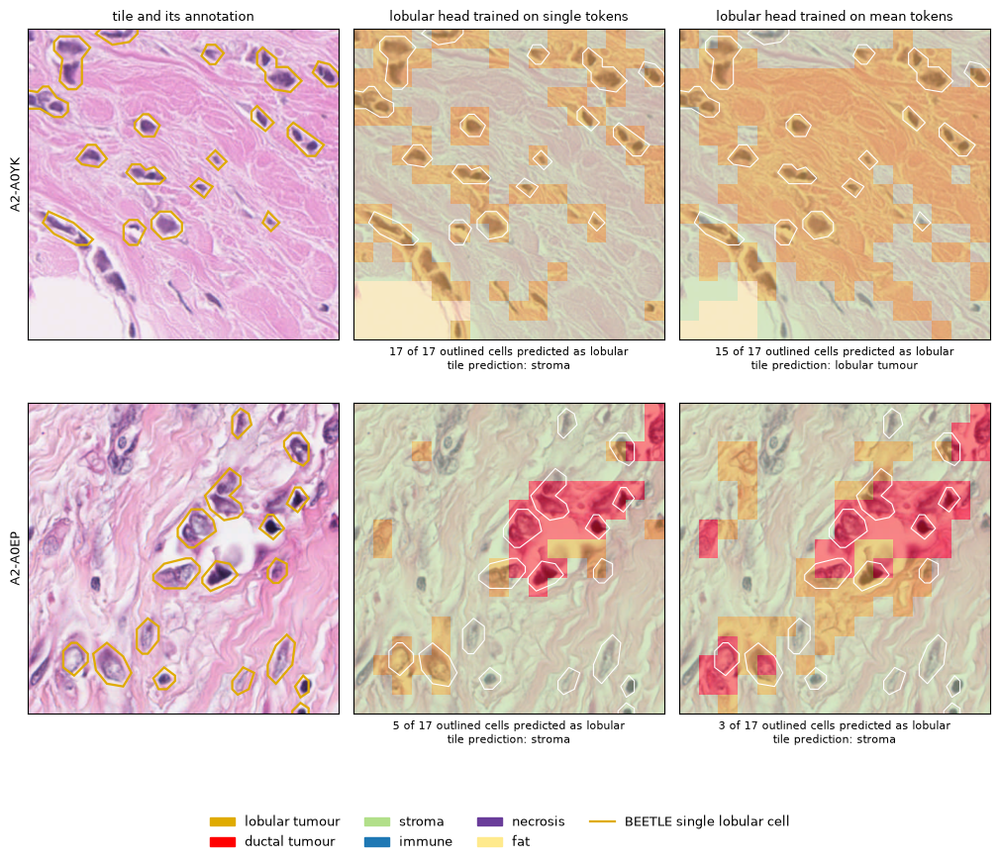

In [10]:
names = ['lobular_most_lobular_A2-A0YK', 'cell_called_ductal_A2-A0EP']
fig, axes = plt.subplots(len(names), 3, figsize=(10.2, 4.5 * len(names)))
for row, name in zip(axes, names):
    img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
    cells = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())['single lobular cells']
    centres = np.array([np.mean(cell, axis=0) for cell in cells])
    cell_tokens = (centres[:, 1] // STEP).astype(int) * GRID + (centres[:, 0] // STEP).astype(int)   # the token at each cell's centre
    tokens = encode(MODELS['H-optimus-0'], [img])[0]

    row[0].imshow(img)
    for cell in cells:
        row[0].add_patch(plt.Polygon(cell, fill=False, ec=LOBULAR_RED, lw=1.6))
    row[0].set_ylabel(PATIENT[name][5:], fontsize=9)
    for ax, model_heads in zip(row[1:], [LOBULAR_HEADS, LOBULAR_MEAN_HEADS]):
        W, b = model_heads['H-optimus-0'][FOLD[HOSPITAL[name]]]
        predictions = (tokens @ W + b).argmax(axis=1)
        tile_logits = tokens.mean(axis=0) @ W + b
        ax.imshow(img)
        ax.imshow(S6_RGBA[predictions].reshape(GRID, GRID, 4), extent=(0, 448, 448, 0), interpolation='nearest')
        for cell in cells:
            ax.add_patch(plt.Polygon(cell, fill=False, ec='white', lw=0.8))
        ax.set_xlabel(f'{(predictions[cell_tokens] == 0).sum()} of {len(cells)} outlined cells predicted as lobular\ntile prediction: {S6[tile_logits.argmax()]}', fontsize=8)

for ax, title in zip(axes[0], ['tile and its annotation', 'lobular head trained on single tokens', 'lobular head trained on mean tokens']):
    ax.set_title(title, fontsize=9)

handles = [Patch(color=c, label=t) for t, c in zip(S6, S6_COLOURS)] + [Line2D([], [], color=LOBULAR_RED, lw=1.6, label='BEETLE single lobular cell')]
plt.setp(axes.flat, xticks=[], yticks=[], xlim=(0, 448), ylim=(448, 0))
fig.tight_layout(rect=(0, 0.8 / fig.get_figheight(), 1, 1))
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=9)
plt.show()

On A2-A0YK, both versions find the scattered cells, but the mean-token head also predicts the collagen between them as lobular and the whole tile as lobular tumour. On A2-A0EP, both miss the cells next to the small group of tumour cells, so this error of section 7 is not caused by training on single tokens.

<a id="part-b"></a>
# Part B. Token-level interpretability and debugging

The dense readout shows where the head finds evidence. It does not show what the encoder represents at a cell, nor where a token's content comes from. In a vision transformer, every token is computed from the whole tile through attention, so a token can carry information from its neighbours. Part B examines single tokens of the lobular head on H-optimus-0.

<a id="section-6"></a>
## 6. Querying with tokens

Similarity between tiles compares averages over many structures. We compare single tokens instead. Each query token is compared with a bank of reference tokens from other patients, each covering a single annotated structure.

**The bank.** 250 tokens for each of four structures. Each token is covered by its annotated structure, sits at the centre of its own tile (row 8, column 8) with its full context, and is predicted as its structure by the lobular head:

- **Lobular cells:** outlined single cells on the BEETLE TCGA evaluation slides whose outline covers at least half of the token.
- **Ductal tumour nuclei:** NuCLS tumour nuclei of ductal patients covering at least 60% of the token, with at least 60% of the nucleus inside it.
- **Fibroblast nuclei:** NuCLS fibroblast nuclei covering at least 40% of the token, with at least 60% of the nucleus inside it.
- **Stroma:** tokens inside NuCLS fields, where every nucleus is outlined, that lie entirely inside a BCSS stroma region and touch no annotated nucleus.

From a pool with the same number of tokens per class, we keep only tokens whose 20 nearest tokens from other patients are at least half of their own class (lobular cells 252 of 307, ductal nuclei 289, fibroblast nuclei 280, stroma 250). The bank therefore holds typical tokens of each class, and a token that the encoder places among another class, such as a lobular cell represented like a fibroblast, is left out. In the final bank, 92% of a token's 20 nearest bank tokens are of its own class (lobular cells 0.92, ductal nuclei 0.96, fibroblast nuclei 0.91, stroma 0.89). All classes are capped at the size of the smallest, so chance is 25% per class. A query's class shares are the classes of its 20 nearest bank tokens, excluding the query's own patient. The selection is computed by `reproduce.py` and shipped as a list of tokens and tiles (`notebook_data/bank_tokens.csv`). The cell below cuts the tiles from the datasets. Section 7 uses the bank to explain errors of the lobular head, and section 8 to see what a cell's token becomes in other tissue.

**Position.** A vision transformer adds a position embedding to every patch, and part of it persists in the final tokens. The bank tokens all sit at one position, while a query can sit anywhere. We checked that removing the mean token of each grid position before comparing, a common correction, changes only about one of a token's 20 nearest bank tokens, so the notebook compares the tokens as they are.


In [11]:
BANK = pd.read_csv('notebook_data/bank_tokens.csv')        # class, source, slide, tile position, token, patient
BANK_CLASSES = ['lobular cell', 'ductal tumour nucleus', 'fibroblast nucleus', 'stroma']
BANK_COLOURS = {'lobular cell': LOBULAR_RED, 'ductal tumour nucleus': TUMOUR_RED, 'fibroblast nucleus': FIBROBLAST, 'stroma': STROMA}
# the annotation that outlines each bank class; a stroma token touches no nucleus and has no outline of its own
BANK_OUTLINE = {'lobular cell': 'tumour outlines', 'ductal tumour nucleus': 'tumour nuclei', 'fibroblast nucleus': 'fibroblast nuclei'}
BANK['tile'] = 'bank_' + BANK.slide.str[:12] + '_' + BANK.x.astype(str) + '_' + BANK.y.astype(str)
bank_tiles = BANK.drop_duplicates('tile')
fetch_tiles({t.tile: (t.source, t.slide, t.x, t.y, t.size) for t in bank_tiles.itertuples()}, DATA_DIR, DATASETS, desc='bank tiles')

# each bank token: H-optimus-0's final token, unit length
bank_tokens = encode(MODELS['H-optimus-0'], [np.asarray(Image.open(DATA_DIR / f'{t}.png')) for t in bank_tiles.tile])
row_of = {t: i for i, t in enumerate(bank_tiles.tile)}
vectors = np.stack([bank_tokens[row_of[t], k] for t, k in zip(BANK.tile, BANK.token)])
BANK_VECTORS = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
del bank_tokens
print(f'{len(BANK)} bank tokens from {len(bank_tiles)} tiles:', BANK.cls.value_counts().to_dict())


def nearest_bank(query, bank, bank_vectors, exclude_patients, k=20):
    """The k bank tokens most similar to a query token (cosine), leaving out the given patients: their rows and similarities."""
    similarity = bank_vectors @ (query / np.linalg.norm(query))
    similarity[bank.patient.isin(exclude_patients).to_numpy()] = -np.inf
    top = np.argsort(-similarity)[:k]
    return bank.iloc[top], similarity[top]

encoding:   0%|          | 0/125 [00:00<?, ?batch/s]

encoding:  22%|██▏       | 27/125 [00:05<00:18,  5.37batch/s]

encoding:  43%|████▎     | 54/125 [00:10<00:13,  5.37batch/s]

encoding:  65%|██████▍   | 81/125 [00:15<00:08,  5.36batch/s]

encoding:  86%|████████▋ | 108/125 [00:20<00:03,  5.35batch/s]

encoding: 100%|██████████| 125/125 [00:23<00:00,  5.36batch/s]

1000 bank tokens from 1000 tiles: {'lobular cell': 250, 'ductal tumour nucleus': 250, 'fibroblast nucleus': 250, 'stroma': 250}


<a id="section-7"></a>
## 7. Errors of the lobular head

We query the bank with four tokens that the lobular head gets wrong.

- **Two outlined single lobular cells** whose nucleus fills most of the token. One lies in collagen and is predicted as stroma (AC-A2FE), on a tile without any tumour prediction. The other is predicted as ductal tumour (A2-A0EP). It lies next to a small group of outlined cells that are also predicted as ductal, while the more scattered cells nearby are predicted as lobular.
- **A ductal tumour nucleus predicted as lobular.** NuCLS outlines every nucleus of its fields, so an error on a ductal tumour nucleus can be checked against an annotation. The lobular head predicts 186 of the 20,691 tumour nuclei of ductal patients as lobular, 62 of them filling their token. We show the one with the highest lobular − ductal logit, on A7-A26I.
- **A ductal tumour token predicted as lobular,** on A7-A4SE, the ductal tile of section 5 with the most lobular predictions. We show the token entirely inside BCSS tumour with the highest lobular − ductal logit.

Each row shows the tile with its annotations and the token's true label, the lobular head's dense readout and its prediction at the token, the token itself, and its six nearest bank tokens. The cyan square marks the token.

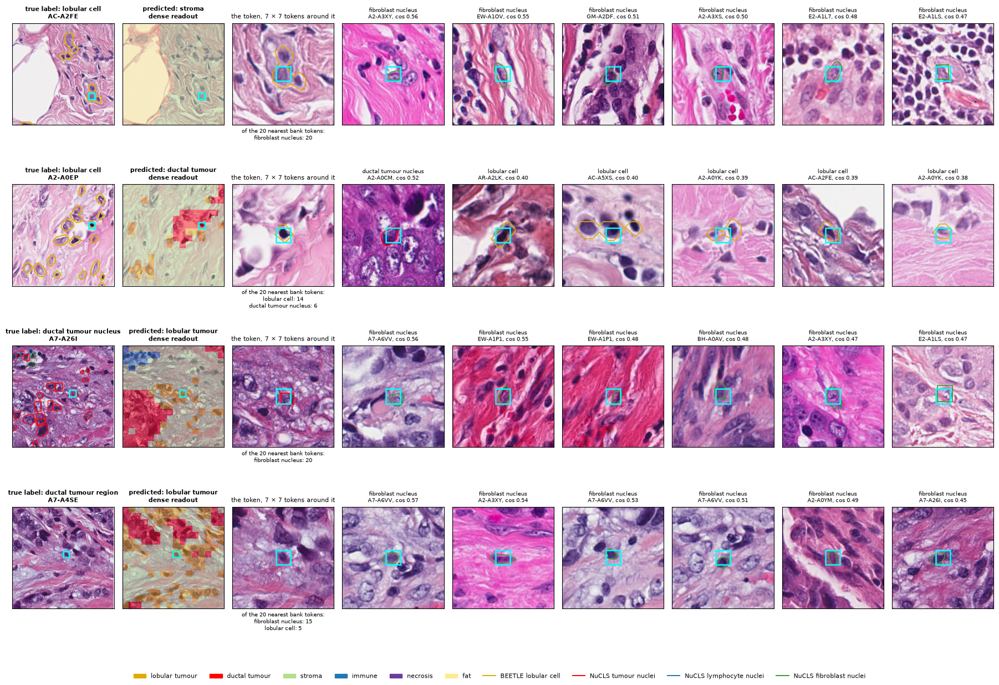

In [12]:
# each case: tile -> token, true label, the annotation that outlines it (None for a token inside a BCSS tumour region)
CASES = {'cell_called_stroma_AC-A2FE': (188, 'lobular cell', 'single lobular cells'),
         'cell_called_ductal_A2-A0EP': (108, 'lobular cell', 'single lobular cells'),
         'nucleus_called_lobular_A7-A26I': (121, 'ductal tumour nucleus', 'tumour nuclei'),
         'ductal_most_lobular_A7-A4SE': (120, 'ductal tumour region', None)}

fig, axes = plt.subplots(4, 9, figsize=(18, 12.6))
for row, (name, (token, true_label, outline_key)) in zip(axes, CASES.items()):
    r, c = divmod(token, GRID)
    img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
    annotation = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())
    tokens = encode(MODELS['H-optimus-0'], [img])[0]
    W, b = LOBULAR_HEADS['H-optimus-0'][FOLD[HOSPITAL[name]]]
    predictions = (tokens @ W + b).argmax(axis=1)
    near, sim = nearest_bank(tokens[token], BANK, BANK_VECTORS, [PATIENT[name]])

    # the whole tile with its annotations, and the dense readout
    row[0].imshow(img)
    for cell in annotation['single lobular cells']:
        row[0].add_patch(plt.Polygon(cell, fill=False, ec=LOBULAR_RED, lw=1.4))
    for kind, colour in NUCLEUS_COLOURS.items():
        for poly in annotation[kind]:
            row[0].add_patch(plt.Polygon(poly, fill=False, ec=colour, lw=1.0))
    row[0].set_title(f'true label: {true_label}\n{PATIENT[name][5:]}', fontsize=8, fontweight='bold')
    row[1].imshow(img)
    row[1].imshow(S6_RGBA[predictions].reshape(GRID, GRID, 4), extent=(0, 448, 448, 0), interpolation='nearest')
    row[1].set_title(f'predicted: {S6[predictions[token]]}\ndense readout', fontsize=8, fontweight='bold')
    for ax in row[:2]:
        ax.add_patch(plt.Rectangle((c * STEP, r * STEP), STEP, STEP, fill=False, ec='cyan', lw=1.8))
        ax.set_xlim(0, 448)
        ax.set_ylim(448, 0)

    # the token, 7 x 7 tokens around it, with the classes of its 20 nearest bank tokens
    row[2].imshow(img)
    if outline_key is not None:                                        # the outline whose centre is nearest the token's centre
        outlines = annotation[outline_key]
        centres = np.array([np.mean(poly, axis=0) for poly in outlines])
        outline = outlines[np.argmin(np.linalg.norm(centres - [(c + 0.5) * STEP, (r + 0.5) * STEP], axis=1))]
        row[2].add_patch(plt.Polygon(outline, fill=False, ec=BANK_COLOURS[true_label], lw=1.2))
    row[2].add_patch(plt.Rectangle((c * STEP, r * STEP), STEP, STEP, fill=False, ec='cyan', lw=1.8))
    row[2].set_xlim((c - 3) * STEP, (c + 4) * STEP)
    row[2].set_ylim((r + 4) * STEP, (r - 3) * STEP)
    row[2].set_title('the token, 7 × 7 tokens around it', fontsize=8)
    row[2].set_xlabel('of the 20 nearest bank tokens:\n' + '\n'.join(f'{cls}: {n}' for cls, n in near.cls.value_counts().items()), fontsize=7)

    # the six nearest bank tokens, each with its own annotation
    for ax, bank_row, s in zip(row[3:], near.iloc[:6].itertuples(), sim[:6]):
        br, bc = divmod(int(bank_row.token), GRID)
        ax.imshow(np.asarray(Image.open(DATA_DIR / f'{bank_row.tile}.png')))
        if bank_row.cls in BANK_OUTLINE:                                       # a stroma token has no outline of its own
            bank_outlines = json.loads((DATA_DIR / f'{bank_row.tile}_annotation.json').read_text())[BANK_OUTLINE[bank_row.cls]]
            bank_centres = np.array([np.mean(poly, axis=0) for poly in bank_outlines])
            bank_outline = bank_outlines[np.argmin(np.linalg.norm(bank_centres - [(bc + 0.5) * STEP, (br + 0.5) * STEP], axis=1))]
            ax.add_patch(plt.Polygon(bank_outline, fill=False, ec=BANK_COLOURS[bank_row.cls], lw=1.2))
        ax.add_patch(plt.Rectangle((bc * STEP, br * STEP), STEP, STEP, fill=False, ec='cyan', lw=1.8))
        ax.set_xlim((bc - 3) * STEP, (bc + 4) * STEP)
        ax.set_ylim((br + 4) * STEP, (br - 3) * STEP)
        ax.set_title(f'{bank_row.cls}\n{bank_row.patient[5:]}, cos {s:.2f}', fontsize=7)

handles = [Patch(color=colour, label=label) for label, colour in zip(S6, S6_COLOURS)]
handles += [Line2D([], [], color=LOBULAR_RED, lw=1.4, label='BEETLE lobular cell')]
handles += [Line2D([], [], color=colour, lw=1.4, label=f'NuCLS {kind}') for kind, colour in NUCLEUS_COLOURS.items()]
plt.setp(axes.flat, xticks=[], yticks=[])
fig.tight_layout(rect=(0, 0.6 / fig.get_figheight(), 1, 1))
fig.legend(handles=handles, loc='lower center', ncol=10, frameon=False, fontsize=8)
plt.show()

- **The missed cell resembles fibroblasts.** All 20 of its nearest bank tokens are fibroblast nuclei. The encoder represents this cell in collagen like a fibroblast, and the head predicts stroma.
- **The cell predicted as ductal resembles both tumour types.** Of its 20 nearest bank tokens, 14 are lobular cells and 6 ductal tumour nuclei. It sits at the edge of the small group of cells that the head predicts as ductal.
- **The ductal nucleus predicted as lobular resembles fibroblasts.** All 20 of its nearest bank tokens are fibroblast nuclei, and none is a ductal tumour nucleus. It lies in an area the head predicts as lobular, next to cohesive tumour at the lower left that the head predicts as ductal.
- **The A7-A4SE token resembles fibroblasts too,** with 15 fibroblast nuclei and 5 lobular cells among its 20 nearest bank tokens. It lies in a strand of tumour cells within stroma.

Three of the four tokens resemble fibroblast nuclei more than either tumour class. For these cells, the encoder's representation is already far from the annotated tumour class, before any head reads it.

In [13]:
# every annotated token of the four tiles: tile, and where its tokens come from
QUERY_SETS = {'AC-A2FE, outlined lobular cells': ('cell_called_stroma_AC-A2FE', 'single lobular cells'),
              'A2-A0EP, outlined lobular cells': ('cell_called_ductal_A2-A0EP', 'single lobular cells'),
              'A7-A26I, ductal tumour nuclei': ('nucleus_called_lobular_A7-A26I', 'tumour nuclei'),
              'A7-A4SE, ductal tumour tokens': ('ductal_most_lobular_A7-A4SE', 'BCSS tumour')}
QUERIES = []
for set_name, (name, source) in QUERY_SETS.items():
    img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
    if source == 'BCSS tumour':                                        # the tokens at least half inside BCSS tumour
        blocks = np.load(DATA_DIR / f'{name}_mask.npy').reshape(GRID, STEP, GRID, STEP).swapaxes(1, 2).reshape(GRID * GRID, -1)
        queried = list(np.flatnonzero((blocks == 0).mean(axis=1) >= 0.5))
    else:                                                              # the token at the centre of each outlined cell or nucleus, once
        outlines = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())[source]
        centres = np.array([np.mean(poly, axis=0) for poly in outlines])
        queried = list(dict.fromkeys((centres[:, 1] // STEP).astype(int) * GRID + (centres[:, 0] // STEP).astype(int)))
    tokens = encode(MODELS['H-optimus-0'], [img])[0]
    W, b = LOBULAR_HEADS['H-optimus-0'][FOLD[HOSPITAL[name]]]
    for t in queried:
        near, _ = nearest_bank(tokens[t], BANK, BANK_VECTORS, [PATIENT[name]])
        QUERIES.append({'set': set_name, 'tile': name, 'token': int(t), 'patient': PATIENT[name], 'prediction': S6[(tokens[t] @ W + b).argmax()],
                        'vector': tokens[t] / np.linalg.norm(tokens[t]), **near.cls.value_counts(normalize=True).reindex(BANK_CLASSES, fill_value=0).to_dict()})
QUERIES = pd.DataFrame(QUERIES)

QUERIES.groupby(['set', 'prediction'], sort=False).agg(tokens=('token', 'size'), **{cls: (cls, 'mean') for cls in BANK_CLASSES}).round(2)

tokens  lobular cell  \
set                             prediction                             
AC-A2FE, outlined lobular cells fat                  1          0.70   
                                stroma               3          0.23   
A2-A0EP, outlined lobular cells stroma               7          0.07   
                                lobular tumour       5          0.98   
                                ductal tumour        5          0.79   
A7-A26I, ductal tumour nuclei   ductal tumour        9          0.32   
                                immune               3          0.08   
                                lobular tumour       7          0.49   
                                stroma               2          0.00   
A7-A4SE, ductal tumour tokens   ductal tumour       39          0.39   
                                lobular tumour      55          0.59   
                                stroma              37          0.17   

                                                ductal tumour nucleus  \
set                             prediction                              
AC-A2FE, outlined lobular cells fat                              0.00   
                                stroma                           0.00   
A2-A0EP, outlined lobular cells stroma                           0.00   
                                lobular tumour                   0.01   
                                ductal tumour                    0.16   
A7-A26I, ductal tumour nuclei   ductal tumour                    0.59   
                                immune                           0.00   
                                lobular tumour                   0.00   
                                stroma                           0.00   
A7-A4SE, ductal tumour tokens   ductal tumour                    0.51   
                                lobular tumour                   0.06   
                                stroma                           0.03   

                                                fibroblast nucleus  stroma  
set                             prediction                                  
AC-A2FE, outlined lobular cells fat                           0.30    0.00  
                                stroma                        0.77    0.00  
A2-A0EP, outlined lobular cells stroma                        0.69    0.24  
                                lobular tumour                0.01    0.00  
                                ductal tumour                 0.05    0.00  
A7-A26I, ductal tumour nuclei   ductal tumour                 0.04    0.06  
                                immune                        0.83    0.08  
                                lobular tumour                0.43    0.08  
                                stroma                        0.22    0.78  
A7-A4SE, ductal tumour tokens   ductal tumour                 0.04    0.06  
                                lobular tumour                0.27    0.08  
                                stroma                        0.16    0.64

On A2-A0EP, the cells predicted as ductal resemble lobular cells (79% of their nearest bank tokens), almost as much as the cells predicted as lobular (98%). The cells predicted as stroma resemble fibroblasts (69%). On AC-A2FE, the three cells predicted as stroma resemble fibroblasts (77%) and lobular cells (23%).

On A7-A26I, the tumour nuclei predicted as ductal resemble ductal nuclei (59%) and lobular cells (32%). Those predicted as lobular resemble lobular cells (49%) and fibroblasts (43%), and never ductal nuclei.

On A7-A4SE, the 55 tumour tokens predicted as lobular resemble lobular cells (59%) much more than ductal nuclei (6%), with a share of fibroblasts (27%). The token shown above, the most lobular of them, leans towards fibroblasts. The 39 tokens predicted as ductal resemble ductal nuclei (51%) and lobular cells (39%). The encoder itself represents these strands of ductal tumour like lobular cells, and the head reads that representation rather than inventing the lobular class. This supports section 5's observation that the lobular class follows the arrangement of tumour cells, not the diagnosis.

**Browser.** The bank and these tokens on a two-dimensional map (UMAP of the tokens, fitted on the bank alone). Dots are bank tokens, coloured by their annotated class. Squares are query tokens, coloured by the lobular head's prediction, and the drop-down chooses which tile's tokens are shown. Hovering shows the 7 × 7-token neighbourhood of a token, with the token in cyan and its annotation outlined, and, for a query, the class shares of its 20 nearest bank tokens. The map only arranges the points. The shares above come from the exact similarities.

In [14]:
from bokeh.io import output_notebook, show
from bokeh.layouts import column
from bokeh.models import ColumnDataSource, CustomJS, HoverTool, Select
from bokeh.plotting import figure

# the 2-D map: fitted on the bank alone, each query placed into it near its bank neighbours
bank_map = umap.UMAP(n_neighbors=15, metric='cosine', random_state=0).fit(BANK_VECTORS)
bank_xy = bank_map.embedding_
query_xy = bank_map.transform(np.stack(QUERIES.vector))


def thumbnail(img, token, outlines, colour, grid=GRID, step=STEP):
    """A 7 x 7-token crop around a token as an inline JPEG for the hover, with the token in cyan and the outline nearest its centre."""
    r, c = divmod(int(token), grid)
    padded = np.pad(img, ((3 * step, 3 * step), (3 * step, 3 * step), (0, 0)), constant_values=255)     # white beyond the tile border
    crop = Image.fromarray(padded[r * step:(r + 7) * step, c * step:(c + 7) * step])
    pen = ImageDraw.Draw(crop)
    if outlines:
        centres = np.array([np.mean(poly, axis=0) for poly in outlines])
        nearest = outlines[np.argmin(np.linalg.norm(centres - [(c + 0.5) * step, (r + 0.5) * step], axis=1))]
        pen.polygon([tuple(point) for point in np.asarray(nearest) - [(c - 3) * step, (r - 3) * step]], outline=colour, width=2)
    pen.rectangle([3 * step, 3 * step, 4 * step - 1, 4 * step - 1], outline='cyan', width=2)
    buffer = io.BytesIO()
    crop.resize((96, 96)).save(buffer, format='JPEG', quality=80)
    return 'data:image/jpeg;base64,' + base64.b64encode(buffer.getvalue()).decode()


bank_points = []
for (x, y), row in tqdm(zip(bank_xy, BANK.itertuples()), total=len(BANK), desc='bank thumbnails', unit='token', mininterval=5):
    img = np.asarray(Image.open(DATA_DIR / f'{row.tile}.png'))
    outlines = []                                                      # a stroma token has no outline of its own
    if row.cls in BANK_OUTLINE:
        outlines = json.loads((DATA_DIR / f'{row.tile}_annotation.json').read_text())[BANK_OUTLINE[row.cls]]
    bank_points.append({'x': x, 'y': y, 'cls': row.cls, 'label': f'bank: {row.cls}', 'patient': row.patient, 'shares': '',
                        'img': thumbnail(img, row.token, outlines, BANK_COLOURS[row.cls])})
bank_points = pd.DataFrame(bank_points)

query_points = []
for (x, y), (_, row) in zip(query_xy, QUERIES.iterrows()):
    img = np.asarray(Image.open(DATA_DIR / f'{row.tile}.png'))
    annotation = json.loads((DATA_DIR / f'{row.tile}_annotation.json').read_text())
    shares = ', '.join(f'{cls} {row[cls]:.0%}' for cls in BANK_CLASSES if row[cls] > 0)
    query_points.append({'x': x, 'y': y, 'set': row.set, 'label': f'query, predicted {row.prediction}', 'patient': row.patient, 'shares': shares,
                         'colour': S6_COLOURS[S6.index(row.prediction)],
                         'img': thumbnail(img, row.token, annotation['single lobular cells'] + annotation['tumour nuclei'], 'cyan')})
query_points = pd.DataFrame(query_points)

output_notebook(hide_banner=True)
plot = figure(width=900, height=650, tools='pan,wheel_zoom,box_zoom,reset', title='Bank tokens (dots) and one set of query tokens (squares)')
for cls, colour in BANK_COLOURS.items():
    plot.scatter('x', 'y', source=ColumnDataSource(bank_points[bank_points.cls == cls]), size=5, color=colour, alpha=0.6, legend_label=f'bank: {cls}')
for prediction in ['lobular tumour', 'ductal tumour', 'stroma']:                  # legend entries for the squares' colours
    plot.scatter([], [], marker='square', size=10, fill_color=S6_COLOURS[S6.index(prediction)], line_color='black', legend_label=f'query, predicted {prediction}')
set_names = list(QUERY_SETS)
query_renderers = [plot.scatter('x', 'y', source=ColumnDataSource(query_points[query_points.set == set_name]), marker='square', size=11,
                                fill_color='colour', line_color='black', visible=(set_name == set_names[0])) for set_name in set_names]
select = Select(title='query tokens', value=set_names[0], options=set_names + ['none'])
select.js_on_change('value', CustomJS(args={'renderers': query_renderers, 'names': set_names},
                                      code='for (let i = 0; i < renderers.length; i++) { renderers[i].visible = (names[i] === cb_obj.value); }'))
plot.add_tools(HoverTool(tooltips='<div><img src="@img" width="140" height="140"><br><b>@label</b><br>@patient<br><span style="font-size: 10px">@shares</span></div>'))
plot.legend.location = 'bottom_left'
plot.legend.label_text_font_size = '8pt'
show(column(select, plot))

bank thumbnails:   0%|          | 0/1000 [00:00<?, ?token/s]

bank thumbnails:  60%|█████▉    | 599/1000 [00:05<00:03, 119.64token/s]

bank thumbnails: 100%|██████████| 1000/1000 [00:08<00:00, 124.97token/s]

<a id="section-8"></a>
## 8. How much of a cell's prediction comes from its surroundings

Every token is computed from the whole tile, so the prediction at a cell can rest on its neighbours. We test this by moving a cell into other tissue. The cell's 3 × 3 window of tokens (about 21 µm) is cut out and pasted at the same place into another tile, the host. The cell's pixels stay the same, and only its surroundings change.

We show two cells from the tiles of section 5, an outlined lobular cell of A2-A0YK and a ductal tumour nucleus of BH-A0B9. The hosts are one ductal tumour tile, one lobular region from BEETLE's training slides and one stroma tile, all from other patients. We picked the cells among the annotated cells of the notebook's tiles, and the hosts among tiles of each kind, where the change is clear. The figure therefore shows the effect at its clearest, not its typical size.

Two controls bound the effect. A host of the cell's own kind changes the surroundings but not their kind, so it shows what the seam and the change of patient do. Greying out the cell's own token, with its surroundings intact, shows what the cell itself contributes.

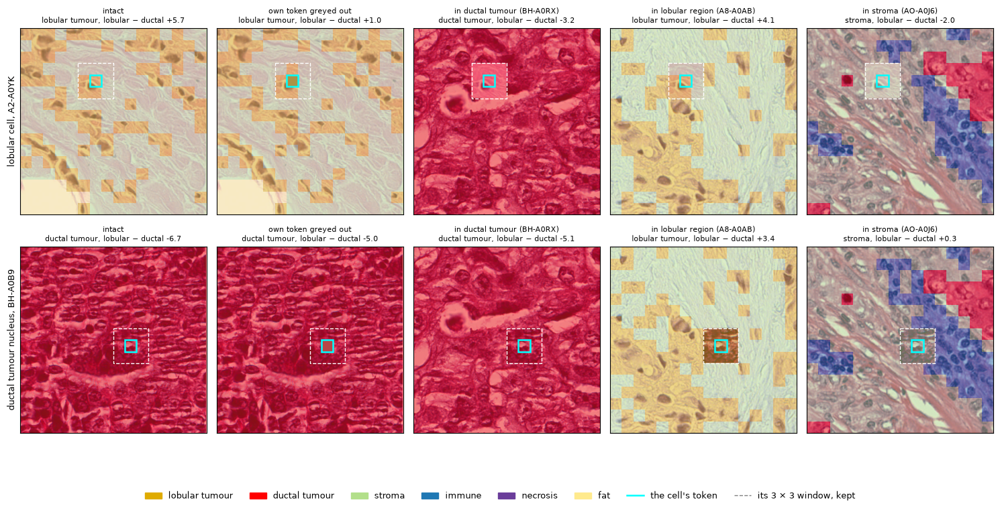

In [15]:
# the two cells: the tile and the token at the cell's centre
CELLS = {'lobular cell': ('lobular_most_lobular_A2-A0YK', 70), 'ductal tumour nucleus': ('ductal_most_ductal_BH-A0B9', 137)}
# one host of each kind, from patients other than the cells'
HOSTS = {'ductal tumour': 'host_ductal_BH-A0RX', 'lobular region': 'host_lobular_A8-A0AB', 'stroma': 'host_stroma_AO-A0J6'}
SWAPPED = {}        # (cell, condition) -> the image, the cell's token, the head's prediction, the patients the bank leaves out

fig, axes = plt.subplots(2, 5, figsize=(15, 7.6))
for row, (kind, (name, token)) in zip(axes, CELLS.items()):
    r, c = divmod(token, GRID)
    window = (slice((r - 1) * STEP, (r + 2) * STEP), slice((c - 1) * STEP, (c + 2) * STEP))     # the cell's 3 x 3 tokens, in pixels
    img = np.asarray(Image.open(DATA_DIR / f'{name}.png'))
    occluded = img.copy()
    occluded[r * STEP:(r + 1) * STEP, c * STEP:(c + 1) * STEP] = 128                         # the cell's own token greyed out
    # each version: condition, title, image, the patients the bank leaves out
    versions = [('intact', 'intact', img, [PATIENT[name]]),
                ('occluded', 'own token greyed out', occluded, [PATIENT[name]])]
    for host_kind, host in HOSTS.items():
        pasted = np.asarray(Image.open(DATA_DIR / f'{host}.png')).copy()
        pasted[window] = img[window]                                                          # the cell's window at the same place in the host
        versions.append((host_kind, f'in {host_kind} ({PATIENT[host][5:]})', pasted, [PATIENT[name], PATIENT[host]]))
    tokens = encode(MODELS['H-optimus-0'], [image for _, _, image, _ in versions])
    W, b = LOBULAR_HEADS['H-optimus-0'][FOLD[HOSPITAL[name]]]
    for ax, (condition, title, image, patients), out in zip(row, versions, tokens):
        predictions = (out @ W + b).argmax(axis=1)
        z = out[token] @ W + b
        SWAPPED[kind, condition] = {'image': image, 'token': out[token], 'prediction': S6[z.argmax()], 'patients': patients}
        ax.imshow(image)
        ax.imshow(S6_RGBA[predictions].reshape(GRID, GRID, 4), extent=(0, 448, 448, 0), interpolation='nearest')
        ax.add_patch(plt.Rectangle(((c - 1) * STEP, (r - 1) * STEP), 3 * STEP, 3 * STEP, fill=False, ec='white', lw=1.0, ls='--'))
        ax.add_patch(plt.Rectangle((c * STEP, r * STEP), STEP, STEP, fill=False, ec='cyan', lw=1.8))
        ax.set_title(f'{title}\n{S6[z.argmax()]}, lobular − ductal {z[0] - z[1]:+.1f}', fontsize=8)
    row[0].set_ylabel(f'{kind}, {PATIENT[name][5:]}', fontsize=9)
handles = [Patch(color=colour, label=label) for label, colour in zip(S6, S6_COLOURS)]
handles += [Line2D([], [], color='cyan', lw=1.8, label="the cell's token"), Line2D([], [], color='grey', lw=1.0, ls='--', label='its 3 × 3 window, kept')]
plt.setp(axes.flat, xticks=[], yticks=[], xlim=(0, 448), ylim=(448, 0))
fig.tight_layout(rect=(0, 0.6 / fig.get_figheight(), 1, 1))
fig.legend(handles=handles, loc='lower center', ncol=8, frameon=False, fontsize=9)
plt.show()

The lobular cell of A2-A0YK is predicted as lobular, with a lobular − ductal logit of +5.7. Pasted into ductal tumour, the same pixels are predicted as ductal tumour (−3.2). In another lobular region the cell stays lobular (+4.1), and in stroma it becomes stroma (−2.0). Greying out its own token lowers the logit to +1.0, and the cell is still predicted as lobular.

The ductal nucleus of BH-A0B9 (−6.7) stays ductal in other ductal tumour (−5.1) and with its own token greyed out (−5.0). Pasted into a lobular region it is predicted as lobular (+3.4), and in stroma as stroma. In both cases the whole pasted window takes the class of the host.

For both cells, surroundings of the other tumour type move the logit further than greying out the cell's own token, by 8.9 against 4.7 for the lobular cell and by 10.1 against 1.7 for the ductal nucleus. They flip the prediction, and greying out does not.

**What the moved token resembles.** The nearest bank tokens of the two cells, intact and in the host of the other tumour type. The first column shows the cell itself with its annotation, its true label and the head's prediction. The other columns show its seven nearest bank tokens, each with its own annotation.

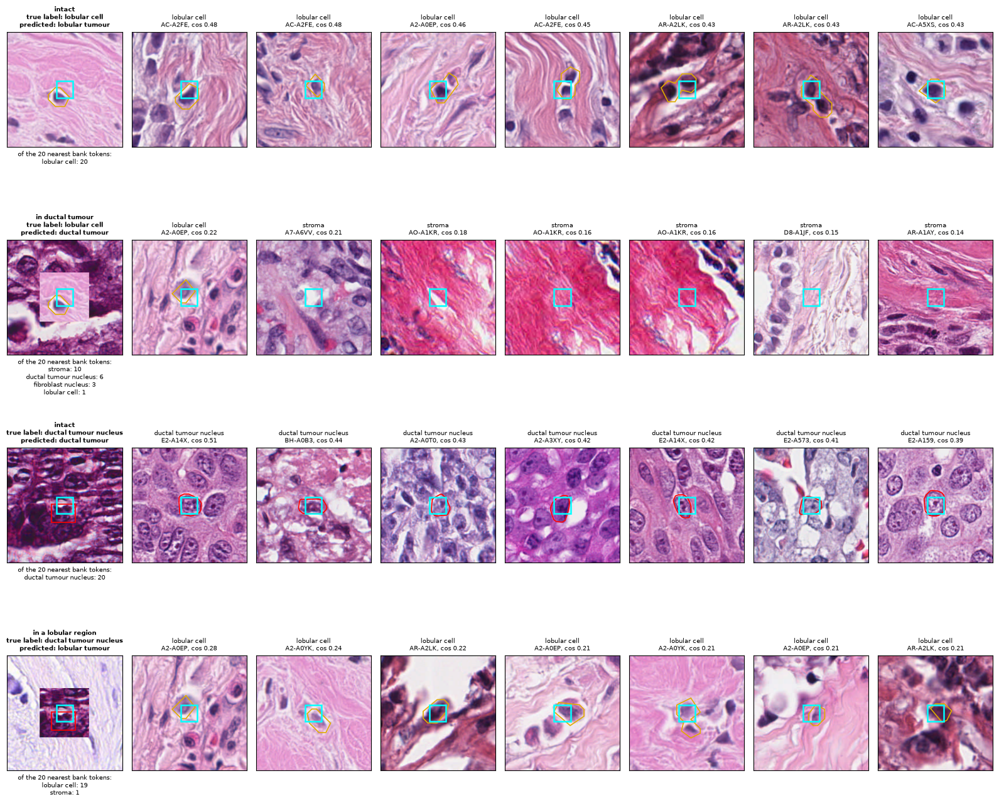

In [16]:
# each row: cell, condition, row title
ROWS = [('lobular cell', 'intact', 'intact'), ('lobular cell', 'ductal tumour', 'in ductal tumour'),
        ('ductal tumour nucleus', 'intact', 'intact'), ('ductal tumour nucleus', 'lobular region', 'in a lobular region')]
fig, axes = plt.subplots(4, 8, figsize=(16, 13.2))
for row, (kind, condition, row_title) in zip(axes, ROWS):
    name, token = CELLS[kind]
    r, c = divmod(token, GRID)
    swapped = SWAPPED[kind, condition]
    near, sim = nearest_bank(swapped['token'], BANK, BANK_VECTORS, swapped['patients'])

    # first column: the cell itself, outlined by its annotation, with its true label and the head's prediction
    outlines = json.loads((DATA_DIR / f'{name}_annotation.json').read_text())[BANK_OUTLINE[kind]]
    centres = np.array([np.mean(poly, axis=0) for poly in outlines])
    outline = outlines[np.argmin(np.linalg.norm(centres - [(c + 0.5) * STEP, (r + 0.5) * STEP], axis=1))]
    row[0].imshow(swapped['image'])
    row[0].add_patch(plt.Polygon(outline, fill=False, ec=BANK_COLOURS[kind], lw=1.2))
    row[0].add_patch(plt.Rectangle((c * STEP, r * STEP), STEP, STEP, fill=False, ec='cyan', lw=1.8))
    row[0].set_xlim((c - 3) * STEP, (c + 4) * STEP)
    row[0].set_ylim((r + 4) * STEP, (r - 3) * STEP)
    row[0].set_title(f'{row_title}\ntrue label: {kind}\npredicted: {swapped["prediction"]}', fontsize=7, fontweight='bold')
    row[0].set_xlabel('of the 20 nearest bank tokens:\n' + '\n'.join(f'{cls}: {n}' for cls, n in near.cls.value_counts().items()), fontsize=7)

    # the seven nearest bank tokens
    for ax, bank_row, s in zip(row[1:], near.iloc[:7].itertuples(), sim[:7]):
        br, bc = divmod(int(bank_row.token), GRID)
        ax.imshow(np.asarray(Image.open(DATA_DIR / f'{bank_row.tile}.png')))
        if bank_row.cls in BANK_OUTLINE:                                       # a stroma token has no outline of its own
            bank_outlines = json.loads((DATA_DIR / f'{bank_row.tile}_annotation.json').read_text())[BANK_OUTLINE[bank_row.cls]]
            bank_centres = np.array([np.mean(poly, axis=0) for poly in bank_outlines])
            bank_outline = bank_outlines[np.argmin(np.linalg.norm(bank_centres - [(bc + 0.5) * STEP, (br + 0.5) * STEP], axis=1))]
            ax.add_patch(plt.Polygon(bank_outline, fill=False, ec=BANK_COLOURS[bank_row.cls], lw=1.2))
        ax.add_patch(plt.Rectangle((bc * STEP, br * STEP), STEP, STEP, fill=False, ec='cyan', lw=1.8))
        ax.set_xlim((bc - 3) * STEP, (bc + 4) * STEP)
        ax.set_ylim((br + 4) * STEP, (br - 3) * STEP)
        ax.set_title(f'{bank_row.cls}\n{bank_row.patient[5:]}, cos {s:.2f}', fontsize=7)
plt.setp(axes.flat, xticks=[], yticks=[])
fig.tight_layout()
plt.show()

Intact, all 20 nearest bank tokens of each cell are of its own class. Moved into ductal tumour, the lobular cell's token is no longer near lobular cells (1 of 20). Its nearest bank tokens are stroma (10), ductal tumour nuclei (6) and fibroblast nuclei (3). Moved into a lobular region, the ductal nucleus' token is near lobular cells (19 of 20). The similarities also fall, from 0.39–0.51 for the seven nearest intact to 0.14–0.28 moved. The moved tokens lie far from every real token, because a pasted window creates tissue that does not exist. That is why the host of the cell's own kind serves as the control.

**In short.** In both cells, the tissue around the cell decides the prediction more than the cell's own token does. The dense readout reports the evidence at a token exactly, but part of that evidence is written into the token by its surroundings.

<a id="part-c"></a>
# Part C. Limitations of the approach

<a id="section-9"></a>
## 9. Limitations

- **Context.** Every token is computed from the whole tile. A token's prediction shows exactly where the head reads its evidence, but not that the evidence comes from the cell under the token. Section 8 shows the surrounding tissue changing a cell's prediction.
- **Resolution.** The readout gives one class per 7 µm square of the patch grid, not per cell. A cell can span several squares, and a square can hold parts of two cells, so each cell is evaluated at the token under its centre.
- **Pooling.** The heads average the tokens, which makes the readout an exact decomposition of the tile prediction. Attention pooling may classify better, but its attention weights are not exact contributions. We trade some accuracy for an explanation that is exact by construction.
- **Frozen encoder.** A linear head can only read what the encoder separates. A lobular cell whose token resembles fibroblasts cannot be recovered by any head (section 7). The tools show what the encoder represents at a token, not how it computes it.
- **Labels.** The readout is only as specific as its labels. Trained on tile labels, the lobular head predicts the collagen between lobular cells as lobular, so small structures need labels at the token (section 5).
- **The tools themselves.** The bank holds typical tokens of four annotated classes, and its answers depend on what it contains. Pasting a cell into another tile creates tissue that does not exist, so a host of the cell's own kind serves as the control (section 8).
- **Other hospitals.** All numbers come from hospitals the heads did not see. The ductal head reaches a median balanced tile accuracy of 0.89–0.91 over 18 hospitals with at least 50 BCSS tiles, and 0.68–0.71 in the worst. Staining and scanners differ between hospitals, and the readout transfers only as well as the encoder does. On Radboudumc's scanner, H-optimus-0 predicts more outlined lobular cells as lobular than on TCGA (0.87 against 0.73), while Phikon-v2 predicts fewer (0.26 against 0.53). Because the readout works at the token, a new site can be checked with a few annotated cells, as done here.
- **Scope of this analysis.** All five encoders are vision transformers. The readout applies to any encoder followed by average pooling and a linear head, including convolutional networks, where it is the class activation map, but we do not test them here. The annotations verify only part of the predictions. BEETLE outlines lobular cells only, in regions of classic lobular carcinoma, so false lobular predictions inside lobular regions and other forms of lobular carcinoma are not evaluated.

**Next steps.** The next step is cell-level lobular labels from more patients and from other forms of lobular carcinoma. Missed lobular cells whose tokens resemble fibroblasts need encoders that represent a single cell in collagen as tumour.